# 샘플 하나 읽기

`reader.py`로 전처리된 MPIIGaze 샘플 하나를 읽어 눈 이미지와 기본 정보(라벨, gaze, head pose)를 확인한다.

먼저 `python -m preprocess.mpii`로 `data/EyeBased/MPIIGaze`를 만들어 두어야 한다.

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np

import reader
from preprocess.mpii_norm import gaze_to_3d

DATA_ROOT = "data/EyeBased/MPIIGaze"
PERSON = "p00"
INDEX = 0

label_path = os.path.join(DATA_ROOT, "Label", f"{PERSON}.label")
image_root = os.path.join(DATA_ROOT, "Image")
assert os.path.exists(label_path), f"{label_path}가 없다. 먼저 python -m preprocess.mpii 를 실행한다."

## 1. 데이터셋 만들기

In [2]:
dataset = reader.loader(label_path, image_root)
print(f"{PERSON} 샘플 수: {len(dataset)}")

p00 샘플 수: 3000


## 2. 라벨 원문

`reader.loader`는 `Image`, `2DGaze`, `2DHead`만 쓴다. 라벨 파일의 모든 칸은 헤더와 짝지어 직접 본다.

In [3]:
with open(label_path) as f:
    header = f.readline().split()
    rows = [ln.split() for ln in f if ln.strip()]

for name, value in zip(header, rows[INDEX]):
    print(f"{name:>10}: {value}")

     Image: p00/1.jpg
    Origin: day08/0069.jpg
  WhichEye: left
    3DHead: -0.5070453089541008,-0.11213903765896885,-0.02908850492750562
    2DGaze: 0.2473605855306808,-0.05211851568699314
    2DHead: -0.11461167521575334,0.5076058965760649
      Rmat: -0.02283722669018121,-0.1708695581189693,-0.03680197652016819
      Smat: 1.0,1.0,1.20470009993699
GazeOrigin: 0.0,1.7763568394002505e-15,600.0


## 3. reader로 샘플 읽기

In [4]:
info, label = dataset[INDEX]
eye = info["eye"]            # (1, 36, 60) float32, 0~1
head_pose = info["head_pose"]  # (yaw, pitch) rad
gaze = label                  # (yaw, pitch) rad

print("name     :", info["name"])
print("eye      :", eye.shape, eye.dtype, f"min={eye.min():.3f} max={eye.max():.3f} mean={eye.mean():.3f}")
print("gaze 2D  :", gaze, "rad ->", np.degrees(gaze).round(2), "deg (yaw, pitch)")
print("head 2D  :", head_pose, "rad ->", np.degrees(head_pose).round(2), "deg (yaw, pitch)")
print("gaze 3D  :", gaze_to_3d(gaze).round(4))

name     : p00/1.jpg
eye      : (1, 36, 60) float32 min=0.000 max=1.000 mean=0.509
gaze 2D  : [ 0.24736059 -0.05211852] rad -> [14.17 -2.99] deg (yaw, pitch)
head 2D  : [-0.11461168  0.5076059 ] rad -> [-6.57 29.08] deg (yaw, pitch)
gaze 3D  : [-0.2445  0.0521 -0.9682]


## 4. 이미지와 gaze 방향

이미지 좌표에서 gaze 화살표는 3D gaze 벡터의 (x, y) 성분 방향이다. 
`gaze_to_3d`에서 x = −cos(pitch)·sin(yaw), y = −sin(pitch)이고, 이미지의 y축은 아래쪽이라 그대로 쓰면 된다. 
오른눈 샘플은 전처리에서 좌우 반전되어 있으므로 이미지와 gaze가 모두 왼눈 기준이다.

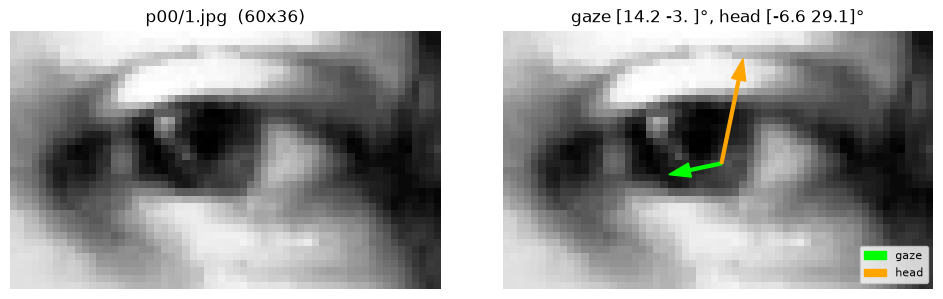

In [5]:
def draw_gaze(ax, img, yaw_pitch, color, label, length=None):
    h, w = img.shape
    length = length or w / 2
    dx = -length * np.cos(yaw_pitch[1]) * np.sin(yaw_pitch[0])
    dy = -length * np.sin(yaw_pitch[1])
    ax.arrow(w / 2, h / 2, dx, dy, color=color, width=0.4, head_width=2, length_includes_head=True, label=label)

img = eye[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"{info['name']}  ({img.shape[1]}x{img.shape[0]})")

axes[1].imshow(img, cmap="gray", vmin=0, vmax=1)
draw_gaze(axes[1], img, gaze, "lime", "gaze")
draw_gaze(axes[1], img, head_pose, "orange", "head")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].set_title(f"gaze {np.degrees(gaze).round(1)}°, head {np.degrees(head_pose).round(1)}°")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. 픽셀 밝기 분포

전처리에서 histogram equalization을 했으므로 0~1 구간에 고르게 퍼져 있어야 한다.

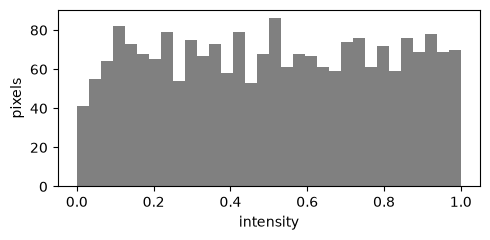

In [6]:
plt.figure(figsize=(5, 2.5))
plt.hist(img.ravel(), bins=32, range=(0, 1), color="gray")
plt.xlabel("intensity")
plt.ylabel("pixels")
plt.tight_layout()
plt.show()